# SINT-666 | Laboratorio 1 — Primera red neuronal
**Universidad CENFOTEC · Trabajo individual**

**Caso simulado:** una entidad desea estudiar patrones asociados con aprobaciones históricas de crédito. El objetivo es practicar redes neuronales, **no automatizar decisiones reales**. Las etiquetas se generaron sintéticamente y no reflejan políticas de una institución.

**Entrega:** notebook ejecutado con código, gráficos, respuestas escritas y conclusiones. Complete las celdas `TODO` y responda las preguntas con sus palabras.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:",tf.__version__)

TensorFlow: 2.21.0


## 1. Cargar y explorar los datos
Los datos (`datos_creditos_estudiantes.csv`) se cargan directamente desde GitHub. ¿Cuántas filas hay? ¿Qué representa cada variable? ¿Qué porcentaje pertenece a cada clase?

In [ ]:
url = 'https://raw.githubusercontent.com/marvinjc/fund_redes_neuronales_python/main/datos_creditos_estudiantes.csv'
df = pd.read_csv(url)
print('Archivo cargado desde GitHub:', url)
print('Dimensiones:', df.shape)
display('Describe:',df.describe().T)
display('Head:',df.head())

Archivo cargado desde GitHub: https://raw.githubusercontent.com/marvinjc/fund_redes_neuronales_python/main/datos_creditos_estudiantes.csv
Dimensiones: (750, 5)


'Describe:'

,count,mean,std,min,25%,50%,75%,max
ingreso_mensual_crc,750.0,944304.438667,371846.250222,280000.00,676952.000,930514.000,1.202096e+06,1980645.000
ratio_endeudamiento,750.0,0.340017,0.151921,0.02,0.225,0.332,4.377500e-01,0.793
antiguedad_laboral_meses,750.0,33.396000,22.068330,1.00,17.000,29.000,4.500000e+01,159.000
atrasos_previos,750.0,0.782667,0.900656,0.00,0.000,1.000,1.000000e+00,6.000
aprobado,750.0,0.381333,0.486038,0.00,0.000,0.000,1.000000e+00,1.000


'Head:'

,ingreso_mensual_crc,ratio_endeudamiento,antiguedad_laboral_meses,atrasos_previos,aprobado
0,627944,0.374,19,1,0
1,976046,0.301,49,0,1
2,474648,0.139,41,1,0
3,348218,0.312,32,0,0
4,1190334,0.300,34,0,1


Proporciones de las clases (%)


aprobado
0    61.866667
1    38.133333
Name: proportion, dtype: float64

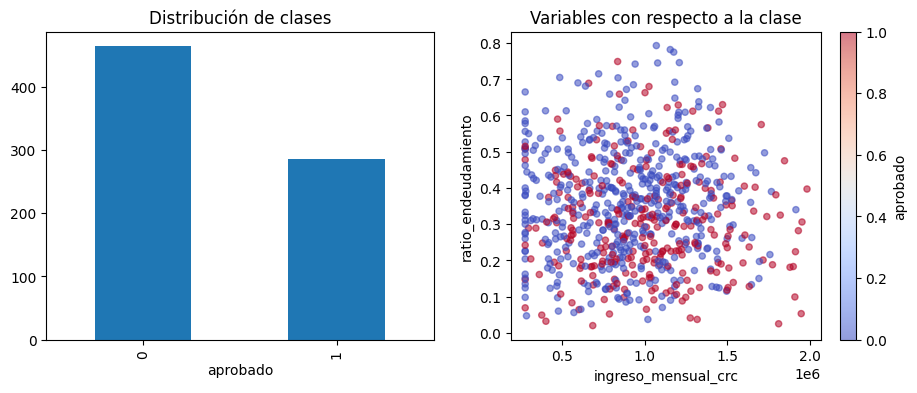

In [ ]:


print("Proporciones de las clases (%)")
display(df.aprobado.value_counts(normalize=True).sort_index() * 100)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.aprobado.value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Distribución de clases")
df.plot.scatter(x="ingreso_mensual_crc", y="ratio_endeudamiento", c="aprobado", cmap="coolwarm", alpha=0.55, ax=ax[1], title="Variables con respecto a la clase")
plt.show()

**Respuesta 1:** Escriba aquí su interpretación y mencione dos posibles limitaciones de los datos sintéticos.

El conjunto de datos tiene 750 registros y 5 columnas. Las variables de entrada son: `ingreso_mensual_crc` (ingreso mensual en colones), `ratio_endeudamiento` (proporción de deuda respecto al ingreso), `antiguedad_laboral_meses` (meses en el empleo actual) y `atrasos_previos` (cantidad de atrasos de pago anteriores). La variable objetivo es `aprobado` (1 = crédito aprobado, 0 = no aprobado).

El 61.9 % de los registros son no aprobados y el 38.1 % aprobados. Es un desbalance moderado, pero importante.

En el gráfico se puede notar que los aprobados tienden a tener mayor ingreso y menor endeudamiento, pero las clases se traslapan bastante, por lo que ninguna variable por sí sola separa bien los casos y el modelo necesitará combinar varias variables.

**Limitaciones de los datos sintéticos:**

1. **No reflejan la realidad:** las etiquetas se generaron con reglas artificiales y no con decisiones reales de una institución.
2. **Son demasiado "limpios" y simples:** no tienen valores faltantes, errores de captura, valores atípicos realistas ni cambios en el tiempo.

## 2. Preparación de datos
Separe las características de `aprobado`. Divida entrenamiento (80%) y prueba (20%) de manera estratificada. Ajuste `StandardScaler` exclusivamente en entrenamiento.

In [ ]:
X = df.drop(columns="aprobado")
y = df.aprobado
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Dimensiones:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Dimensiones: (600, 4) (150, 4) (600,) (150,)


In [ ]:
escalador= StandardScaler()
escalador.fit(X_train)
X_train_s=escalador.transform(X_train)
X_test_s=escalador.transform(X_test)

**Respuesta 2:** ¿Por qué no debemos ajustar el escalador con los datos de prueba?

Porque se produce una fuga de datos (*data leakage*). Al ajustarse, el `StandardScaler` calcula la media y la desviación estándar de cada variable. Si se incluyen los datos de prueba, esas estadísticas contendrán información del conjunto que debería ser totalmente nuevo para el modelo. Es decir, el modelo tendría información "del futuro", y la evaluación sería artificialmente optimista y no reflejaría con sinceridad el desempeño con datos nunca vistos. Por eso el escalador se ajusta solo con `X_train` y luego se usa para transformar tanto el entrenamiento como la prueba.

Por esta misma razón, el ajuste del escalador debe realizarse **después** de la partición.


## 3. Diseñar una red neuronal
Cree una arquitectura 4 → 8 (ReLU) → 1 (Sigmoid), usando `keras.Sequential`. Compile con Adam, binary crossentropy y accuracy.

In [ ]:
modelo = keras.Sequential([keras.Input(shape=(4,)), keras.layers.Dense(8, activation="relu"), keras.layers.Dense(1, activation="sigmoid")])
modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49 (196.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

**Respuesta 3:** ¿Cuántos parámetros entrenables tiene? Justifique el cálculo manualmente.

Fórmula por capa: parámetros = (entradas × neuronas) + neuronas

- Capa oculta: (4 × 8) + 8 = 40
- Capa de salida: (8 × 1) + 1 = 9

Total: 40 + 9 = 49 parámetros entrenables.


## 4. Entrenar
Utilice 30 épocas, batch size 16 y validation_split 0.2. Grafique pérdida y exactitud de entrenamiento/validación.

Inicio entrenamiento


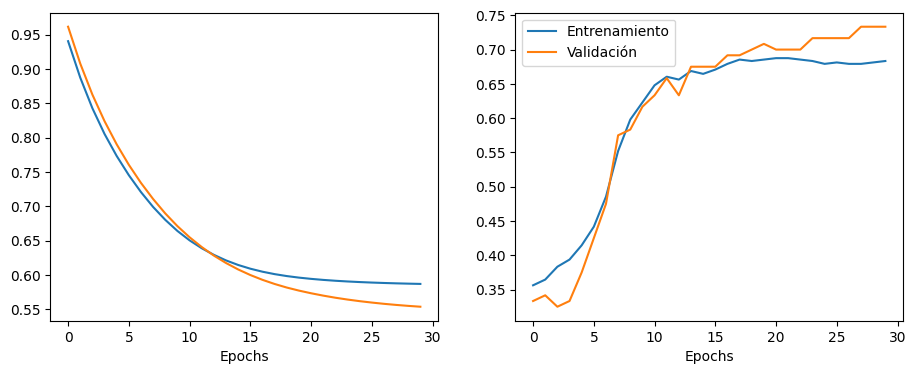

In [ ]:
print("Inicio entrenamiento")
hist = modelo.fit(X_train_s, y_train, epochs=30, batch_size=16, validation_split=0.2, verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for j, metrica in enumerate(["loss", "accuracy"]):
  ax[j].plot(hist.history[metrica], label="Entrenamiento")
  ax[j].plot(hist.history[f"val_{metrica}"], label="Validación")
  ax[j].set_xlabel("Epochs")
plt.legend()
plt.show()

**Respuesta 4:** ¿Las curvas muestran sobreajuste, subajuste o no permiten concluirlo claramente? Justifique.

No permiten concluir claramente que exista sobreajuste o subajuste

## 5. Evaluar y predecir
Evalúe una única vez con el conjunto de prueba. Obtenga probabilidades, conviértalas a clases con umbral 0.5 y muestre una matriz de confusión.

In [ ]:
# TODO: modelo.evaluate(X_test_s, y_test)
# TODO: modelo.predict(X_test_s)
# TODO: matriz de confusión
# TODO: mostrar 3 probabilidades e interpretarlas

**Respuesta 5:** ¿Qué errores son más frecuentes? ¿Por qué una probabilidad de 0.7 no garantiza un resultado?

## 6. Experimento
Entrene **otro** modelo cambiando la activación oculta de ReLU a Tanh, manteniendo las demás condiciones y la misma división. Compare curvas y métricas. No elija el mejor modelo basándose repetidamente en test.

In [ ]:
# TODO: definir modelo_tanh, compilar, entrenar y comparar en validación

**Respuesta 6:** ¿Qué diferencias observó? ¿Son suficientes para afirmar que una función es siempre mejor?

## 7. Investigación breve
**Pregunta:** ¿por qué una red con varias capas lineales consecutivas no obtiene la misma capacidad de representación que una red con activaciones no lineales?

Incluya: explicación propia, ejemplo matemático sencillo, comparación de Sigmoid/ReLU/Tanh, un gráfico y al menos dos fuentes técnicas confiables. Referencia recomendada: https://keras.io/api/layers/activations/

**Respuesta 7:**

Varias capas lineales seguidas equivalen a **una sola capa lineal**, por lo que solo pueden representar relaciones rectas. Las activaciones no lineales permiten aprender relaciones curvas y más complejas.

**Ejemplo:** si $h = 2x + 1$ y $y = 3h - 2$, entonces $y = 3(2x + 1) - 2 = 6x + 1$, que sigue siendo una recta. En cambio, $\text{ReLU}(x) + \text{ReLU}(-x) = |x|$ forma una "V", imposible de lograr solo con capas lineales.

| Función | Rango | Uso típico |
|---|---|---|
| Sigmoid | (0, 1) | Salida en clasificación binaria |
| Tanh | (−1, 1) | Capas ocultas, centrada en cero |
| ReLU | [0, ∞) | Capas ocultas, la más usada por ser simple y rápida |

**Fuentes:**
1. Keras. *Layer activation functions*. https://keras.io/api/layers/activations/
2. Goodfellow, I., Bengio, Y. y Courville, A. (2016). *Deep Learning*, cap. 6. MIT Press. https://www.deeplearningbook.org/contents/mlp.html

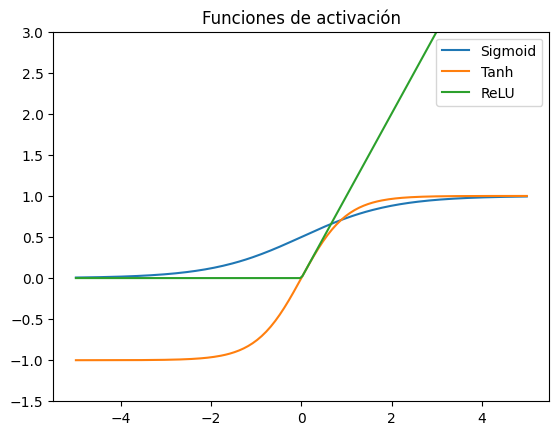

In [ ]:
x = np.linspace(-5, 5, 200)
plt.plot(x, 1 / (1 + np.exp(-x)), label="Sigmoid")
plt.plot(x, np.tanh(x), label="Tanh")
plt.plot(x, np.maximum(0, x), label="ReLU")
plt.title("Funciones de activación")
plt.ylim(-1.5, 3)
plt.legend()
plt.show()

## Preguntas de análisis

**1. ¿Qué variables utiliza la red neuronal para generar sus predicciones?**

Usa cuatro variables:

- `ingreso_mensual_crc`: cuánto gana la persona al mes.
- `ratio_endeudamiento`: qué tanto debe en comparación con lo que gana.
- `antiguedad_laboral_meses`: cuánto tiempo lleva en su trabajo.
- `atrasos_previos`: cuántas veces se ha atrasado en sus pagos.

Con esas cuatro, la red predice `aprobado` (1 = sí, 0 = no), que es la respuesta que tiene que aprender.

**2. ¿Por qué es importante normalizar los datos?**

Porque los números vienen en tamaños muy diferentes. El ingreso anda por los cientos de miles de colones y el endeudamiento es algo como 0.34. Si los dejamos así, la red se fija más en el ingreso solo porque es un número más grande, aunque no sea lo más importante. Es como comparar precios en colones con precios en dólares sin convertirlos: la comparación sale injusta. Al normalizar, todo queda en una escala parecida y cada dato tiene la misma oportunidad.

**3. ¿Qué función de activación utilizó en la capa de salida y por qué?**

Usé Sigmoid. Lo que hace es convertir el resultado final en un número entre 0 y 1, y eso se puede leer como una probabilidad. Si la red da 0.8, es como si dijera "estoy bastante seguro de que este crédito se aprueba"; si da 0.2, lo contrario. Como aquí la respuesta es solo sí o no, me pareció la opción que más sentido tiene.

**4. ¿Qué representan los pesos de una red neuronal?**

Yo lo veo como el "criterio" de la red. Cada peso dice cuánta atención le pone a cada dato. Al inicio la red no sabe nada y los pesos son al azar, como alguien que apenas empieza en un trabajo. Con el entrenamiento se va equivocando, corrige y ajusta esos pesos poco a poco. Al final, ahí queda guardado lo que aprendió.

**5. ¿Considera que el modelo obtuvo resultados adecuados? Justifique.**

Aceptables, pero no excelentes. El modelo acierta cerca de 7 de cada 10 veces, mientras que decir "no aprobado" a todos ya acertaría 6 de cada 10. Aprendió algo, pero poco, y como seguía mejorando al final, podría beneficiarse de más entrenamiento.

## 8. Conclusiones y entrega
Redacte tres aprendizajes, una limitación del ejercicio y una mejora para una próxima versión. Entregue el notebook ejecutado en Moodle. **No usar para aprobación de créditos reales.**

**Respuesta 8:**

**Aprendizajes:**
1. Antes de entrenar hay que preparar los datos: separarlos en entrenamiento y prueba, y escalarlos para que ninguna variable domine solo por tener números más grandes.
2. Una red neuronal aprende ajustando sus pesos poco a poco; incluso una red pequeña (49 parámetros) puede encontrar patrones.
3. Un porcentaje de aciertos no dice mucho por sí solo: hay que compararlo con algo simple, como decir "no aprobado" a todos.
4. Entendí que sin funciones de activación como ReLU, apilar capas no sirve de mucho: al final todo se reduce a una sola operación lineal.
5. Las curvas de entrenamiento y validación ayudan a saber si el modelo está aprendiendo bien, si se está "memorizando" los datos o si le falta aprender.
6. Calcular a mano los parámetros (49 en este caso) me ayudó a ver que una red es, en el fondo, un montón de multiplicaciones y sumas que se van ajustando.


**Limitación:** los datos son inventados y solo tienen cuatro variables, así que el modelo no refleja cómo se aprueban créditos en la vida real.

**Mejora:** entrenar por más épocas, ya que el modelo todavía seguía mejorando, y separar los datos de forma estratificada para mantener la misma proporción de aprobados y no aprobados.